# Analyse exploratoire des données

**Responsable de ce notebook** : Étudiant 2
**Livrable associé** : `reports/rapport_analyse_exploratoire.md` + figures dans `reports/figures/`

## Périmètre (qui fait quoi)
- **Ce notebook** : constater, mesurer, visualiser, interpréter.
- **Étudiant 3** : décider et corriger (valeurs manquantes, doublons, types, colonnes à retirer).
- **Étudiant 4** : découper les données et définir le protocole d'évaluation.

> Règle : on **documente** les problèmes, on ne **modifie pas** les données brutes et on ne fait ni encodage, ni mise à l'échelle, ni découpage.

## Plan
| Section | Contenu | État |
|---|---|---|
| 0 | Configuration | fait |
| 1 | Structure du jeu de données | fait |
| 2 | Valeurs manquantes, valeurs cachées, doublons, cohérence des variables | fait |
| 3 à 9 | Statistiques, classes, familles de variables, TLD, corrélations, anomalies, synthèse | complété — à relire |

## 0. Configuration
**Objectif** : imports, chemins (`../data/raw/`), options d'affichage, dossier de sortie des figures (`../reports/figures/`).

In [38]:
# imports des libraries necessaires

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
# Chemins et options d'affichage

# Chemins relatifs à periode-1/notebooks/
DATA_RAW = Path("../data/raw")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42  # pour tout échantillonnage (graphiques lourds sur 235 795 lignes)

# Affichage
pd.set_option("display.max_columns", None)   # 56 colonnes
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

def save_fig(name):
    """Enregistre la figure courante dans reports/figures/."""
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

# Vérification : que contient data/raw ?
print(sorted(p.name for p in DATA_RAW.iterdir()))

['dataset.csv']


## 1. Structure du jeu de données
**Objectif** : savoir exactement ce qu'on a.

**Questions auxquelles répondre**
- Combien de lignes et de colonnes ?
- Quels types de variables (numériques, binaires, texte) ?
- Quelle est la taille mémoire ?
- Quelle est la variable cible et que signifie chaque valeur ?
- Quelles colonnes sont des identifiants ou du texte ?

In [40]:
# chargement du jeu de données complet (csv brut) et structure du DataFrame

df = pd.read_csv(DATA_RAW / "dataset.csv")
df.head(10)

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.000,1.000,0.523,0.062,3,1,0,0,0.000,18,0.581,0,0.000,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000,0.000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.000,0.667,0.033,0.050,2,1,0,0,0.000,9,0.391,0,0.000,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.556,55.556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.000,0.867,0.029,0.064,2,2,0,0,0.000,15,0.517,0,0.000,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.667,46.667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.000,1.000,0.523,0.058,3,1,0,0,0.000,13,0.500,0,0.000,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000,0.000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.000,1.000,0.080,0.059,3,1,0,0,0.000,20,0.606,0,0.000,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000,100.000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1
5,23107.txt,https://www.globalreporting.org,30,www.globalreporting.org,23,0,org,100.000,1.000,0.080,0.061,3,1,0,0,0.000,17,0.567,0,0.000,0,0,0,1,0.033,1,1210,737,1,gri - home,0.000,0.000,0,0,1,0,0,1,1,1,0,1,0,1,0,0,0,0,1,35,1,11,86,0,14,1
6,23034.txt,https://www.saffronart.com,25,www.saffronart.com,18,0,com,100.000,1.000,0.523,0.064,3,1,0,0,0.000,12,0.480,0,0.000,0,0,0,1,0.040,1,1024,984,1,0,0.000,0.000,1,0,1,1,1,0,2,4,0,1,0,1,0,0,0,0,1,32,4,14,44,2,17,1
7,696732.txt,https://www.nerdscandy.com,25,www.nerdscandy.com,18,0,com,100.000,1.000,0.523,0.060,3,1,0,0,0.000,12,0.480,0,0.000,0,0,0,1,0.040,1,514,399,1,nerds candy,100.000,100.000,1,0,1,0,0,1,0,1,0,1,1,0,0,0,0,0,1,24,2,22,36,0,15,1
8,739255.txt,https://www.hyderabadonline.in,29,www.hyderabadonline.in,22,0,in,100.000,1.000,0.005,0.057,2,1,0,0,0.000,16,0.552,0,0.000,0,0,0,1,0.034,1,2371,12913,1,hyderabadonline - business listing in hyderaba...,100.000,100.000,0,1,1,0,0,1,0,0,0,1,1,1,1,0,0,0,1,71,4,9,40,1,317,1
9,14486.txt,https://www.aap.org,18,www.aap.org,11,0,org,100.000,1.000,0.080,0.070,3,1,0,0,0.000,5,0.278,0,0.000,0,0,0,1,0.056,1,2730,481,1,home,0.000,0.000,1,1,1,0,0,1,0,2,0,1,0,0,0,0,0,0,1,10,1,12,173,6,65,1


In [41]:
# Dimensions, types, mémoire

print("Dimensions du DataFrame : ", df.shape)
print('-'*50)
df.info(memory_usage="deep")
print('-'*50)
print("Types de données : ", df.dtypes.value_counts())
print('-'*50)
print("Valeurs de la colonne 'label' : ", df["label"].value_counts())   # attendu : 134 850 (1) et 100 945 (0)

Dimensions du DataFrame :  (235795, 56)
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64

In [42]:
# Classification des colonnes par famille (identifiant / texte / binaire / numérique)

id_cols = ["FILENAME"]
text_cols = ["URL", "Domain", "TLD", "Title"]
target = "label"                                 # variable cible (0 ou 1)

num_cols = [c for c in df.columns if c not in id_cols + text_cols + [target]]
binary_cols = [c for c in num_cols if df[c].nunique() <= 2]
continuous_cols = [c for c in num_cols if c not in binary_cols]

print("Classification des colonnes par famille :")
print("=" * 45)

categories = {
    "Identifiants": id_cols,
    "Texte": text_cols,
    "Binaires hors cible": binary_cols,
    "Numériques non binaires": continuous_cols
}

for categorie, colonnes in categories.items():
    print(f"\n{categorie} ({len(colonnes)} colonnes)")
    print("-" * 35)

    for col in colonnes:
        print(f"  - {col}")

Classification des colonnes par famille :

Identifiants (1 colonnes)
-----------------------------------
  - FILENAME

Texte (4 colonnes)
-----------------------------------
  - URL
  - Domain
  - TLD
  - Title

Binaires hors cible (19 colonnes)
-----------------------------------
  - IsDomainIP
  - HasObfuscation
  - IsHTTPS
  - HasTitle
  - HasFavicon
  - Robots
  - IsResponsive
  - NoOfURLRedirect
  - NoOfSelfRedirect
  - HasDescription
  - HasExternalFormSubmit
  - HasSocialNet
  - HasSubmitButton
  - HasHiddenFields
  - HasPasswordField
  - Bank
  - Pay
  - Crypto
  - HasCopyrightInfo

Numériques non binaires (31 colonnes)
-----------------------------------
  - URLLength
  - DomainLength
  - URLSimilarityIndex
  - CharContinuationRate
  - TLDLegitimateProb
  - URLCharProb
  - TLDLength
  - NoOfSubDomain
  - NoOfObfuscatedChar
  - ObfuscationRatio
  - NoOfLettersInURL
  - LetterRatioInURL
  - NoOfDegitsInURL
  - DegitRatioInURL
  - NoOfEqualsInURL
  - NoOfQMarkInURL
  - NoOfAmpers

### Colonnes `NoOfURLRedirect` et `NoOfSelfRedirect`
Elles sont classées binaires alors que leur nom évoque un comptage : on vérifie leurs valeurs, et qu'aucune colonne binaire n'est constante.

In [43]:
for c in ["NoOfURLRedirect", "NoOfSelfRedirect"]:
    print(df[c].value_counts(), "\n")

# Une colonne binaire est-elle en réalité constante ?
constantes = [c for c in binary_cols if df[c].nunique() < 2]
print("Colonnes binaires constantes :", constantes if constantes else "aucune")

NoOfURLRedirect
0    204331
1     31464
Name: count, dtype: int64 

NoOfSelfRedirect
0    226338
1      9457
Name: count, dtype: int64 

Colonnes binaires constantes : aucune


### Interprétation de la section 1 :

**Faits**
- Le jeu contient **235 795 lignes et 56 colonnes** (54 variables, plus `label` et `FILENAME`), soit environ 166 Mo en mémoire. Les effectifs sont conformes à la documentation UCI : **134 850 URL légitimes** (`label = 1`) et **100 945 URL de phishing** (`label = 0`).
- Cinq familles de colonnes : 1 identifiant (`FILENAME`, à ignorer selon la documentation), 4 colonnes de texte (`URL`, `Domain`, `TLD`, `Title`), 19 binaires, 31 numériques non binaires (comptages, ratios, scores) et la cible.
- `NoOfURLRedirect` et `NoOfSelfRedirect` sont décrites comme des nombres de redirections, mais elles ne prennent que les valeurs 0 et 1 (respectivement 13,3 % et 4,0 % de lignes à 1). On les traite comme des **indicateurs** (redirection présente ou non).
- Aucune colonne binaire n'est constante.

**Hypothèse / limite**
- La raison pour laquelle ces deux colonnes sont plafonnées à 1 n'est pas établie (plafonnement ou détection de simple présence). À vérifier dans l'article de référence (Prasad et Chandra, 2024), sinon à noter comme limite.

**Point d'attention** : la classe d'intérêt pour la détection est le phishing, codé **0**. Les métriques devront préciser la classe positive.

## 2. Valeurs manquantes, valeurs cachées, doublons et cohérence
**Objectif** : repérer les problèmes de qualité **sans les corriger** (la correction relève de l'étudiant 3).

- 2.1 Valeurs manquantes classiques et chaînes vides
- 2.2 Valeurs cachées : `Title`, zéros de contenu
- 2.3 Doublons (lignes, URL, domaines)
- 2.4 Cohérence entre `URLLength` et le texte de l'URL
- 2.5 Forme des URL : page d'accueil ou chemin
- 2.6 Synthèse de la section 2

### 2.1 Valeurs manquantes classiques et chaînes vides

In [44]:
# Valeurs manquantes classiques

manquantes = df.isna().sum()
manquantes = manquantes[manquantes > 0]
print("Colonnes avec valeurs manquantes :", manquantes.to_dict() if len(manquantes) else "aucune")

Colonnes avec valeurs manquantes : aucune


In [45]:
# Chaînes vides ou espaces dans les colonnes texte
for c in text_cols:
    print(c, "→ vides :", df[c].str.strip().eq("").sum())

URL → vides : 0
Domain → vides : 0
TLD → vides : 0
Title → vides : 0


### 2.2 Valeurs cachées
Comme `isna()` ne détecte rien : on cherche des valeurs qui jouent le rôle de « absent » (cohérence `HasTitle` / `Title`, zéros de contenu).

In [46]:
# Cohérence HasTitle / Title

print("HasTitle=0 mais Title rempli :", ((df["HasTitle"] == 0) & (df["Title"].str.strip() != "")).sum())
print("HasTitle=1 mais Title vide   :", ((df["HasTitle"] == 1) & (df["Title"].str.strip() == "")).sum())

HasTitle=0 mais Title rempli : 32714
HasTitle=1 mais Title vide   : 0


In [47]:
# Que contiennent les titres quand HasTitle = 0 ?
anom = df[(df["HasTitle"] == 0) & (df["Title"].str.strip() != "")]
print(anom["Title"].value_counts().head(10))
print("\nRépartition des classes parmi ces lignes :")
print(anom["label"].value_counts(normalize=True))
print("\nPart de HasTitle par classe (colonnes = classes) :")
print(pd.crosstab(df["HasTitle"], df["label"], normalize="columns"))

Title
0    32714
Name: count, dtype: int64

Répartition des classes parmi ces lignes :
label
0   0.995
1   0.005
Name: proportion, dtype: float64

Part de HasTitle par classe (colonnes = classes) :
label        0     1
HasTitle            
0        0.322 0.001
1        0.678 0.999


In [48]:
# Zéros qui pourraient signifier « absent » (page non chargée ?)
for c in ["LineOfCode", "LargestLineLength", "NoOfImage", "NoOfJS", "NoOfCSS"]:
    n = (df[c] == 0).sum()
    print(f"{c}: {n} zéros ({n / len(df):.2%})")

LineOfCode: 0 zéros (0.00%)
LargestLineLength: 0 zéros (0.00%)
NoOfImage: 85521 zéros (36.27%)
NoOfJS: 79311 zéros (33.64%)
NoOfCSS: 83737 zéros (35.51%)


In [49]:
# Part de zéros par classe (label 0 = phishing, label 1 = légitime)
cols = ["NoOfImage", "NoOfJS", "NoOfCSS"]
print(df.groupby("label")[cols].agg(lambda s: (s == 0).mean()))

       NoOfImage  NoOfJS  NoOfCSS
label                            
0          0.834   0.771    0.803
1          0.010   0.011    0.020


### Interprétation de la sections 2.1 et 2.2 :

**Faits**
- Aucune valeur manquante, aucune chaîne vide (`URL`, `Domain`, `TLD`, `Title`), conformément à la documentation UCI.
- **Valeur cachée** : 32 714 lignes ont `HasTitle = 0` alors que `Title` est rempli. Dans tous les cas, le contenu est la chaîne `"0"` : c'est un **marqueur d'absence déguisé**, invisible pour `isna()`. L'inverse (`HasTitle = 1` avec un titre vide) n'existe pas.
- Ces lignes sont à 99,5 % des phishing : environ 32 % des URL de phishing n'ont pas de titre, contre 0,1 % des URL légitimes.
- `LineOfCode` et `LargestLineLength` ne valent jamais 0. En revanche, `NoOfImage`, `NoOfJS` et `NoOfCSS` valent 0 pour environ 34 à 36 % des lignes, avec un contraste très net entre classes :

| Part de lignes à 0 | Phishing | Légitime |
|---|---|---|
| `NoOfImage` | 83,4 % | 1,0 % |
| `NoOfJS` | 77,1 % | 1,1 % |
| `NoOfCSS` | 80,3 % | 2,0 % |

**Hypothèses (non vérifiées)**
- La cause de ces pages « sans ressource » peut être une page réellement minimaliste, une page déjà retirée au moment de la collecte, ou un téléchargement incomplet. Les données ne permettent pas de trancher.

**Conséquence pour la fiabilité** : ces variables de contenu séparent presque les deux classes à elles seules. Un modèle qui apprend « page sans image, JS ni CSS = phishing » obtiendrait de bons scores sur ce jeu mais serait fragile face à un phishing soigné ou à une page non téléchargée. À examiner en section 7.

*Correction à relire : les différences de proportions montrent une association avec la classe, mais ne suffisent pas à mesurer les performances d’une règle ou d’un modèle. « Séparent presque les classes » doit être compris comme une piste à évaluer, pas comme un résultat de classification.*


### 2.3 Doublons (constat uniquement)
- Lignes entièrement identiques ?
- URL répétées ? Domaines répétés ?
- Même URL avec des **labels contradictoires** ?
- Risque de fuite de données si ces doublons se retrouvent à la fois en train et en test (à signaler à l'étudiant 4).


*Correction à relire : numérotation harmonisée avec le plan.*

In [50]:
# Doublons (lignes, URL, Domain, labels contradictoires)

# Lignes identiques (on retire FILENAME, qui est unique par ligne et masquerait les doublons)
print("Lignes identiques hors FILENAME :", df.drop(columns="FILENAME").duplicated().sum())

print("URL en double    :", df["URL"].duplicated().sum())
print("Domain en double :", df["Domain"].duplicated().sum())

# Même URL avec des labels contradictoires
nb_labels = df.groupby("URL")["label"].nunique()
print("URL avec labels contradictoires :", (nb_labels > 1).sum())

Lignes identiques hors FILENAME : 0
URL en double    : 425
Domain en double : 15709
URL avec labels contradictoires : 0


In [51]:
# Doublons d'URL : lignes concernées, classes, colonnes qui diffèrent d'une copie à l'autre
dup_rows = df[df["URL"].duplicated(keep=False)]
print(len(dup_rows), "lignes pour", dup_rows["URL"].nunique(), "URL distinctes")
print(dup_rows["label"].value_counts())

nb_valeurs_distinctes = dup_rows.drop(columns="FILENAME").groupby("URL").nunique()
print("\nNombre de paires d'URL où la colonne diffère (10 premières colonnes) :")
print((nb_valeurs_distinctes > 1).sum().sort_values(ascending=False).head(10))

850 lignes pour 425 URL distinctes
label
0    850
Name: count, dtype: int64

Nombre de paires d'URL où la colonne diffère (10 premières colonnes) :
URLLength                     425
LetterRatioInURL              424
SpacialCharRatioInURL         407
NoOfOtherSpecialCharsInURL    289
DegitRatioInURL               250
URLCharProb                   136
NoOfLettersInURL              129
Title                          96
LargestLineLength              72
LineOfCode                     37
dtype: int64


In [52]:
# Exemples de paires dupliquées
dup_rows.sort_values("URL")[["URL", "URLLength", "LetterRatioInURL", "Title"]].head(6)

,URL,URLLength,LetterRatioInURL,Title
219489,http://2f3a.reicrut-chat.workers.dev/,37,0.622,0
57609,http://2f3a.reicrut-chat.workers.dev/,36,0.639,0
227564,http://34.149.138.117/,21,0.000,34149138
27166,http://34.149.138.117/,22,0.000,34149138
147448,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,62,0.661,595221selcdnqwerty-ohdhdjejnnad-najahhyindex4htm
189978,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,63,0.667,595221selcdnqwerty-ohdhdjejnnad-najahhyindex4html


In [53]:
# Domaines répétés : lesquels, et de quelle classe ?
print(df["Domain"].value_counts().head(10))

dom = df.groupby("Domain")["label"].agg(["size", "mean"])      # mean = part de label 1
rep = dom[dom["size"] > 1]
print("\n", len(rep), "domaines répétés")
print("100 % phishing  :", (rep["mean"] == 0).sum(), "domaines,", rep.loc[rep["mean"] == 0, "size"].sum(), "lignes")
print("100 % légitimes :", (rep["mean"] == 1).sum(), "domaines,", rep.loc[rep["mean"] == 1, "size"].sum(), "lignes")
print("mixtes          :", ((rep["mean"] > 0) & (rep["mean"] < 1)).sum())

Domain
ipfs.io                         1197
docs.google.com                  526
mail.deliverylifesupport.com     370
cloudflare-ipfs.com              359
storageapi.fleek.co              318
gateway.pinata.cloud             275
gateway.ipfs.io                  249
ipfs.litnet.work                 223
cf-ipfs.com                      190
s3.amazonaws.com                 182
Name: count, dtype: int64

 5526 domaines répétés
100 % phishing  : 5472 domaines, 21123 lignes
100 % légitimes : 0 domaines, 0 lignes
mixtes          : 54


In [54]:
# Domaines « mixtes » (présents dans les deux classes) : taille et part de légitimes
stats = df.groupby("Domain")["label"].agg(["nunique", "size", "mean"])
mixtes = stats[stats["nunique"] > 1].sort_values("size", ascending=False)
print(len(mixtes), "domaines mixtes (liste complète)")
print(mixtes)

# Deux exemples examinés
exemples = ["www.linkedin.com", "www.mod.gov.in"]
print(df[df["Domain"].isin(exemples)][["URL", "label", "Title"]].to_string())

54 domaines mixtes (liste complète)
                               nunique  size  mean
Domain                                            
www.indushealthplus.com              2     4 0.250
www.kashmirhills.com                 2     3 0.333
www.poompuhar.com                    2     3 0.333
www.1x.com                           2     2 0.500
www.sexobazaar.com                   2     2 0.500
www.laemchabanggolf.com              2     2 0.500
www.leaguelineup.com                 2     2 0.500
www.linkedin.com                     2     2 0.500
www.mod.gov.in                       2     2 0.500
www.nnpstv.com                       2     2 0.500
www.noip.com                         2     2 0.500
www.nsupdate.info                    2     2 0.500
www.privateinternetaccess.com        2     2 0.500
www.sydneyartsguide.com.au           2     2 0.500
www.iplocation.net                   2     2 0.500
www.tracemyip.org                    2     2 0.500
www.tribalpages.com                  2     2 0

### Interprétation de la section 2.3 :

**Faits**
- **Aucune ligne identique** (hors `FILENAME`), mais **425 URL apparaissent deux fois** (850 lignes). Elles sont toutes de classe phishing, sans label contradictoire.
- Ces doublons ne sont pas des copies exactes : `URLLength` diffère dans les 425 paires et `LetterRatioInURL` dans 424, alors que le contenu de la page est presque identique (`LineOfCode` ne diffère que dans 37 paires). Un `drop_duplicates()` classique ne les détecterait pas.
- **15 709 doublons de `Domain`**, répartis sur **5 526 domaines répétés** : 5 472 sont 100 % phishing (21 123 lignes), 54 sont mixtes, **aucun n'est 100 % légitime**. Chaque domaine légitime n'apparaît donc qu'une fois, sauf cas mixtes.
- Les domaines les plus fréquents sont des plateformes d'hébergement ou de partage, tous de classe phishing : `ipfs.io` (1 197 lignes), `docs.google.com` (526), `cloudflare-ipfs.com` (359), `s3.amazonaws.com` (182)… Les dix premiers représentent 3 889 lignes.
- Les 54 domaines mixtes sont petits (2 à 4 lignes). Dans les deux exemples examinés, ce sont des **URL différentes d'un même site** : pour `linkedin.com`, la racine est légitime et `/slink?code=…` est étiquetée phishing ; pour `mod.gov.in`, la version `https` est légitime et la version `http` est étiquetée phishing.

**Hypothèses (non vérifiées)**
- Les paires dupliquées seraient la même page traitée deux fois avec une convention de calcul légèrement différente (voir 2.4).
- Les domaines mixtes peuvent être du bruit d'étiquette ou des cas particuliers réels : une revue manuelle de ces 54 cas est faisable.

**Conséquence** : un découpage purement aléatoire pourrait placer des centaines de lignes d'un même domaine à la fois en entraînement et en test, et les deux copies d'une même URL de part et d'autre du découpage. Cela ne concerne presque que la classe phishing.

### 2.4 Cohérence entre `URLLength` et le texte de l'URL
On compare `URLLength` à la longueur réelle du texte de la colonne `URL`. Écart = `len(URL) − URLLength`.

In [55]:
# Écart entre la longueur réelle du texte de l'URL et URLLength
ecart = df["URL"].str.len() - df["URLLength"]
ecart.name = "ecart"

print("URLLength != len(URL) :", (ecart != 0).sum(), f"({(ecart != 0).mean():.1%})")
print(ecart.value_counts().sort_index())

URLLength != len(URL) : 187151 (79.4%)
ecart
0      48644
1     187149
4          1
35         1
Name: count, dtype: int64


In [56]:
# L'écart dépend-il de la classe ? (effectifs exacts)
print(pd.crosstab(ecart, df["label"]))

# Écarter l'hypothèse d'espaces invisibles aux extrémités
print("\nURL avec espaces aux extrémités :", (df["URL"] != df["URL"].str.strip()).sum())

label      0       1
ecart               
0      48644       0
1      52299  134850
4          1       0
35         1       0

URL avec espaces aux extrémités : 0


In [57]:
# Les deux cas atypiques (écart > 1) et les URL contenant des caractères mal décodés
print(df.loc[ecart > 1, ["URL", "URLLength", "label"]].to_string())

moji = df["URL"].str.contains("Ã|Â|â€", regex=True)
print("\nURL avec caractères mal décodés :")
print(pd.crosstab(moji, df["label"]))

                                                                                                                                         URL  URLLength  label
127839  https://22017-5502.s3.webspace.re/privatkunden/Ã£Å“berblick/sicherheit/notfallhilfe/firmenkunden/geschÃ£Â¤ftskunden/kontakt/clients/        128      0
158380                                  https://vinted.6545657.xyz/p5ci5kt9Ã¢â‚¬â€¹Ã¢â‚¬â€¹Ã¢â‚¬â€¹Ã¢â‚¬â€¹Ã¢â‚¬â€¹Ã¢â‚¬â€¹Ã¢â‚¬â€¹/tsidom/7         65      0

URL avec caractères mal décodés :
label       0       1
URL                  
False  100943  134850
True        2       0


### Interprétation de la section 2.4 : 

**Faits**
- `URLLength` est différent de la longueur du texte de `URL` pour **187 151 lignes (79,4 %)**. L'écart vaut 1 dans presque tous les cas (187 149 lignes) ; deux lignes seulement présentent un écart de 4 et de 35.
- **L'écart dépend de la classe** : il vaut 1 pour 100 % des URL légitimes, mais pour 51,8 % seulement des phishing. Les 48 644 lignes à écart 0 sont **toutes des phishing**.
- Il n'y a pas d'espaces invisibles aux extrémités des URL.
- Les deux écarts atypiques sont des URL dont le texte est mal décodé (suites de type `Ã£`, `Ã¢â‚¬`), toutes deux phishing. Cela ne concerne que 2 lignes.

**Hypothèses (non vérifiées)**
- Pour une partie des lignes, les variables de l'URL semblent calculées sans le dernier caractère (dans les paires dupliquées, la ligne la plus courte perd par exemple le `l` final de `.html`).
- Les deux classes n'ont peut-être pas été traitées avec la même convention. La cause dans la chaîne de collecte ne peut pas être déduite des données.

**Conséquence** : `URLLength` n'est pas « fausse », mais elle n'est pas égale à `len(URL)`. Recalculer ces variables à partir du texte d'une URL saisie dans l'application web (période 3) suppose de connaître la convention utilisée à l'entraînement.

### 2.5 Forme des URL : page d'accueil ou chemin
Une URL est dite **réduite à son domaine** si, une fois retirés le schéma (`http://`, `https://`) et le `/` final, elle est égale à la colonne `Domain` (donc sans chemin ni paramètres).

In [58]:
# Les URL sont-elles réduites à leur domaine ? (par classe)
sans_schema = df["URL"].str.replace(r"^https?://", "", regex=True).str.rstrip("/")
racine = sans_schema.eq(df["Domain"])
racine.name = "reduite_au_domaine"

print(pd.crosstab(racine, df["label"]))
print()
print(pd.crosstab(racine, df["label"], normalize="columns"))

label                   0       1
reduite_au_domaine               
False               28689       0
True                72256  134850

label                  0     1
reduite_au_domaine            
False              0.284 0.000
True               0.716 1.000


### Interprétation de la section 2.5 :

**Faits**
- **Les 134 850 URL légitimes sont toutes réduites à leur domaine** (aucun chemin, aucun paramètre).
- Chez les phishing, 72 256 URL (71,6 %) sont réduites à leur domaine et **28 689 (28,4 %) comportent un chemin ou des paramètres**.
- Dans ce jeu, **toute URL avec chemin est donc un phishing** (28 689 sur 28 689). La paire `linkedin.com` vue en 2.3 suit ce schéma.

**Conséquence pour la fiabilité**
- Le jeu ne contient **aucune URL légitime avec chemin**, alors que c'est le cas le plus courant en usage réel. Un modèle peut apprendre « URL longue ou complexe = phishing » : ses scores sur ce jeu ne mesurent pas sa capacité à reconnaître une page légitime profonde, et les faux positifs sur ce type d'URL sont un risque non mesuré.
- Piste de test pour la période 2 : ajouter un chemin ou un paramètre à une URL légitime et observer si la prédiction bascule (idée à tester, pas un résultat).

*Correction à relire : le test effectué ici mesure une égalité textuelle après retrait du schéma et des barres finales. Une inégalité peut aussi venir d’un port ou d’une différence de représentation. La section 8 vérifie séparément la présence d’un chemin, de paramètres ou d’un fragment avec un parseur.*

### 2.6 Synthèse de la section 2

**Hypothèse de travail** : plusieurs indicateurs diffèrent fortement entre les deux classes, ce qui suggère que les URL légitimes et de phishing n'ont peut-être pas été collectées ni traitées par la même chaîne. Ce n'est **pas vérifié**, mais si c'est le cas, un modèle risque d'apprendre la **provenance** d'une URL plutôt que le phishing : d'excellents scores sur ce jeu, une fiabilité douteuse sur d'autres URL.

| Indicateur | Phishing | Légitime |
|---|---|---|
| Écart de longueur nul (`len(URL) = URLLength`) | 48,2 % | 0 % |
| `HasTitle = 0` (`Title = "0"`) | ≈ 32 % | 0,1 % |
| `NoOfImage = 0` | 83,4 % | 1,0 % |
| `NoOfJS = 0` | 77,1 % | 1,1 % |
| `NoOfCSS = 0` | 80,3 % | 2,0 % |
| Domaine répété (hors mixtes) | 5 472 domaines | 0 |
| URL réduite à son domaine | 71,6 % | 100 % |

**Ce qu'on peut affirmer** : ces écarts sont mesurés sur tout le jeu. **Ce qu'on ne peut pas affirmer** : leur cause. Les résultats de la section 2 sont à transmettre aux étudiants 3 et 4 (voir `resume_transmissions.md`).

## 3. Statistiques descriptives
On décrit les valeurs sans modifier `df`. La moyenne est sensible aux extrêmes ; la médiane décrit le centre et le 99e percentile indique la valeur en dessous de laquelle se trouvent environ 99 % des observations. L’asymétrie (`skew`) décrit la forme de la distribution, pas la qualité des données.

`continuous_cols` contient ici des **numériques non binaires**, y compris des comptages entiers, et pas uniquement des variables continues.

In [59]:
desc = df[continuous_cols].describe(percentiles=[.25, .5, .75, .99]).T
desc["skew"] = df[continuous_cols].skew()
display(desc.sort_values("skew", ascending=False))

,count,mean,std,min,25%,50%,75%,99%,max,skew
NoOfCSS,235795.000,6.333,74.866,0.000,0.000,2.000,8.000,51.000,35820.000,464.404
NoOfObfuscatedChar,235795.000,0.025,1.876,0.000,0.000,0.000,0.000,0.000,447.000,204.684
NoOfJS,235795.000,10.522,22.312,0.000,0.000,6.000,15.000,64.000,6957.000,140.436
NoOfEqualsInURL,235795.000,0.062,0.935,0.000,0.000,0.000,0.000,2.000,176.000,114.985
NoOfEmptyRef,235795.000,2.378,17.641,0.000,0.000,0.000,1.000,31.000,4887.000,106.826
NoOfAmpersandInURL,235795.000,0.025,0.836,0.000,0.000,0.000,0.000,0.000,149.000,106.717
NoOfiFrame,235795.000,1.589,5.763,0.000,0.000,0.000,1.000,21.000,1602.000,97.677
NoOfDegitsInURL,235795.000,1.881,11.887,0.000,0.000,0.000,0.000,27.000,2011.000,94.878
NoOfPopup,235795.000,0.222,3.871,0.000,0.000,0.000,0.000,4.000,602.000,84.953
NoOfExternalRef,235795.000,49.263,161.027,0.000,1.000,10.000,57.000,423.000,27516.000,65.900


In [60]:
# Pour une variable strictement binaire, sa moyenne est la proportion de 1.
assert df[binary_cols].isin([0, 1]).all().all()
display((df[binary_cols].mean() * 100).sort_values().to_frame("pourcentage_de_1"))
part_modale = df[num_cols].apply(lambda s: s.value_counts(normalize=True).iloc[0])
print("Variables constantes :", part_modale[part_modale.eq(1)].index.tolist())
display((part_modale[part_modale.ge(.99)] * 100).sort_values(ascending=False).to_frame("valeur_majoritaire_pct"))

,pourcentage_de_1
HasObfuscation,0.206
IsDomainIP,0.271
Crypto,2.347
NoOfSelfRedirect,4.011
HasExternalFormSubmit,4.399
HasPasswordField,10.226
Bank,12.709
NoOfURLRedirect,13.344
Pay,23.701
Robots,26.654


Variables constantes : []


,valeur_majoritaire_pct
HasObfuscation,99.794
NoOfObfuscatedChar,99.794
ObfuscationRatio,99.794
IsDomainIP,99.729
NoOfAmpersandInURL,99.624


In [61]:
display(df[text_cols].nunique().to_frame("valeurs_distinctes"))
print("TLD présents moins de 10 fois :", df["TLD"].value_counts().lt(10).sum())
print("Title = '0' :", df["Title"].eq("0").sum())
print("Dont HasTitle = 0 :", (df["Title"].eq("0") & df["HasTitle"].eq(0)).sum())
display(df.loc[df["Title"].eq("0") & df["HasTitle"].eq(1), ["FILENAME", "Title", "HasTitle", "label"]])

,valeurs_distinctes
URL,235370
Domain,220086
TLD,695
Title,197874


TLD présents moins de 10 fois : 408
Title = '0' : 32719
Dont HasTitle = 0 : 32714


,FILENAME,Title,HasTitle,label
6,23034.txt,0,1,1
13,858208.txt,0,1,1
15,252332.txt,0,1,1
35,584755.txt,0,1,1
36,603823.txt,0,1,1


### Interprétation
- `URLLength` a une médiane de 27, une moyenne de 34,573 et un maximum de 6 097 : quelques grandes valeurs tirent la moyenne vers le haut. `NoOfCSS` a une médiane de 2, un percentile 99 de 51 et un maximum de 35 820. Ces extrêmes demandent un examen ; ils ne sont pas automatiquement des erreurs.
- Aucune variable numérique n’est constante. Une modalité représente toutefois plus de 99 % des lignes pour plusieurs variables : un signal rare peut rester utile pour une sous-population ; on ne le supprime pas sur ce seul critère.
- Les 695 TLD comprennent 408 modalités présentes moins de 10 fois. Les conclusions sur ces petits groupes seront fragiles.
- *Correction à relire concernant la section 2 : 32 719 titres valent `"0"`, dont 32 714 avec `HasTitle = 0` et cinq avec `HasTitle = 1`. L’hypothèse d’un marqueur d’absence concerne les premiers ; les cinq autres cas ne permettent pas d’affirmer une absence.*

## 4. Répartition des classes et ordre du fichier
Les proportions quantifient le déséquilibre. Les noms explicites évitent d’inverser la cible : **0 = phishing, 1 = légitime**, selon la documentation UCI. Un bloc de lignes consécutives ne représente pas une période chronologique.

,effectif,pourcentage
label,,
Phishing,100945,42.810
Légitime,134850,57.190


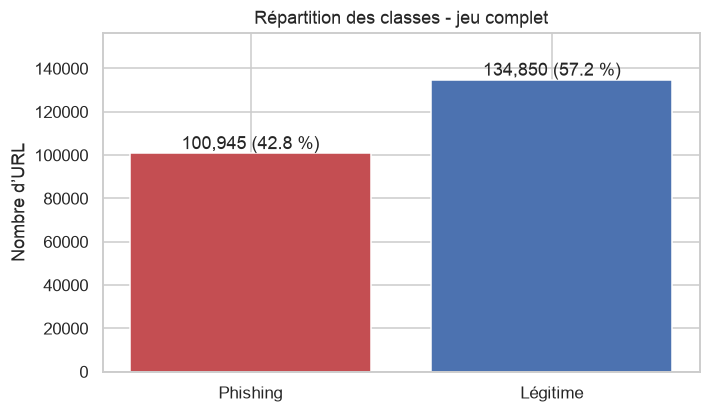

In [62]:
class_names = {0: "Phishing", 1: "Légitime"}
class_order = ["Phishing", "Légitime"]
colors = ["#c44e52", "#4c72b0"]
classes = df["label"].value_counts().reindex([0, 1]).to_frame("effectif")
classes["pourcentage"] = classes["effectif"] / len(df) * 100
classes.index = classes.index.map(class_names)
display(classes)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(classes.index, classes["effectif"], color=colors)
for i, row in enumerate(classes.itertuples()):
    ax.text(i, row.effectif, f"{row.effectif:,} ({row.pourcentage:.1f} %)", ha="center", va="bottom")
ax.set(title="Répartition des classes - jeu complet", ylabel="Nombre d’URL")
ax.set_ylim(0, classes["effectif"].max() * 1.16)
save_fig("01_repartition_classes")
plt.show()

,bloc,effectif,phishing_pct
0,1,23580,40.471
1,2,23580,41.921
2,3,23580,42.740
3,4,23580,43.142
4,5,23580,43.681
5,6,23579,43.836
6,7,23579,42.996
7,8,23579,43.060
8,9,23579,43.195
9,10,23579,43.064


Changements de classe entre lignes consécutives : 115186


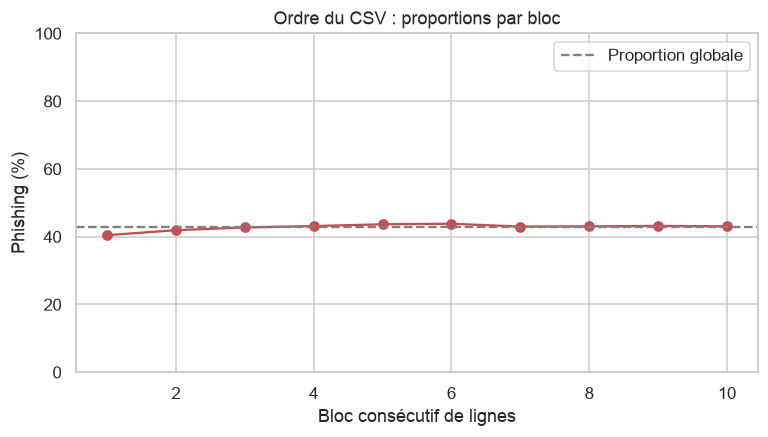

In [63]:
# Dix blocs consécutifs de taille presque égale, sans réordonner les lignes.
blocs = np.array_split(df["label"].to_numpy(), 10)
ordre = pd.DataFrame({"bloc": range(1, 11), "effectif": [len(b) for b in blocs],
                      "phishing_pct": [(b == 0).mean() * 100 for b in blocs]})
display(ordre)
transitions = df["label"].ne(df["label"].shift()).iloc[1:].sum()
print("Changements de classe entre lignes consécutives :", transitions)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ordre["bloc"], ordre["phishing_pct"], marker="o", color=colors[0])
ax.axhline(classes.loc["Phishing", "pourcentage"], linestyle="--", color="gray", label="Proportion globale")
ax.set(xlabel="Bloc consécutif de lignes", ylabel="Phishing (%)", ylim=(0, 100), title="Ordre du CSV : proportions par bloc")
ax.legend()
save_fig("02_ordre_classes")
plt.show()

### Interprétation
Le jeu contient 100 945 URL de phishing (42,8 %) et 134 850 légitimes (57,2 %). Le déséquilibre est modéré. Prédire systématiquement « légitime » donnerait 57,2 % d’accuracy, mais ne détecterait aucun phishing : l’accuracy seule ne suffit donc pas.

Les changements de classe et les proportions par bloc permettent de vérifier que le fichier n’est pas simplement séparé en deux classes. Ils ne démontrent ni un mélange aléatoire ni une indépendance des observations. Le découpage reste à la charge de l’étudiant 4, en tenant compte des URL et domaines répétés.

On compte 115 186 changements de classe entre lignes voisines. La proportion de phishing par bloc varie de 40,47 % à 43,84 % : le premier bloc diffère légèrement des suivants, sans séparation complète des classes.

## 5. Comparaisons entre classes
On utilise toutes les lignes. Les boîtes présentent la médiane, les quartiles et les moustaches usuelles (1,5 fois l’écart interquartile). Les points extrêmes sont masqués **sur ces figures seulement** pour garder la lecture possible ; aucune ligne n’est supprimée. `log1p(x)` signifie `log(1 + x)` : cette représentation conserve les zéros et comprime les grandes valeurs.

URLLength        DomainLength        NoOfSubDomain      
            median   mean       median   mean        median  mean
label                                                            
Phishing    34.000 45.720       22.000 24.465         1.000 1.169
Légitime    26.000 26.229       19.000 19.229         1.000 1.162

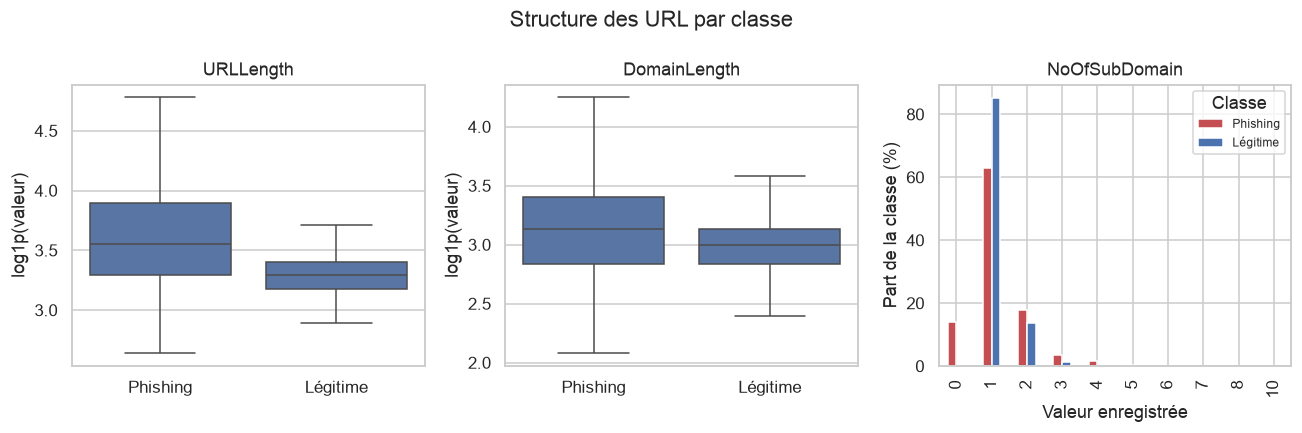

In [64]:
# Une copie destinée aux graphiques, sans altérer df.
plot_df = df.assign(Classe=df["label"].map(class_names))
def compare_numeric(columns, filename, title):
    display(df.groupby("label")[columns].agg(["median", "mean"]).rename(index=class_names))
    fig, axes = plt.subplots(1, len(columns), figsize=(4 * len(columns), 4))
    for ax, col in zip(np.atleast_1d(axes), columns):
        if col == "NoOfSubDomain":
            frequencies = pd.crosstab(df[col], df["label"], normalize="columns").rename(columns=class_names) * 100
            frequencies.plot.bar(ax=ax, color=colors)
            ax.set(title=col, xlabel="Valeur enregistrée", ylabel="Part de la classe (%)")
            ax.legend(title="Classe", fontsize=8)
            continue
        view = pd.DataFrame({"Classe": plot_df["Classe"], "valeur": np.log1p(df[col])})
        sns.boxplot(data=view, x="Classe", y="valeur", order=class_order, showfliers=False, ax=ax)
        ax.set(title=col, xlabel="", ylabel="log1p(valeur)")
    fig.suptitle(title)
    fig.tight_layout()
    save_fig(filename)
    plt.show()

compare_numeric(["URLLength", "DomainLength", "NoOfSubDomain"], "03_structure_numerique", "Structure des URL par classe")

label,Phishing,Légitime
IsDomainIP,0.632,0.000
IsHTTPS,49.224,100.000
HasObfuscation,0.480,0.000


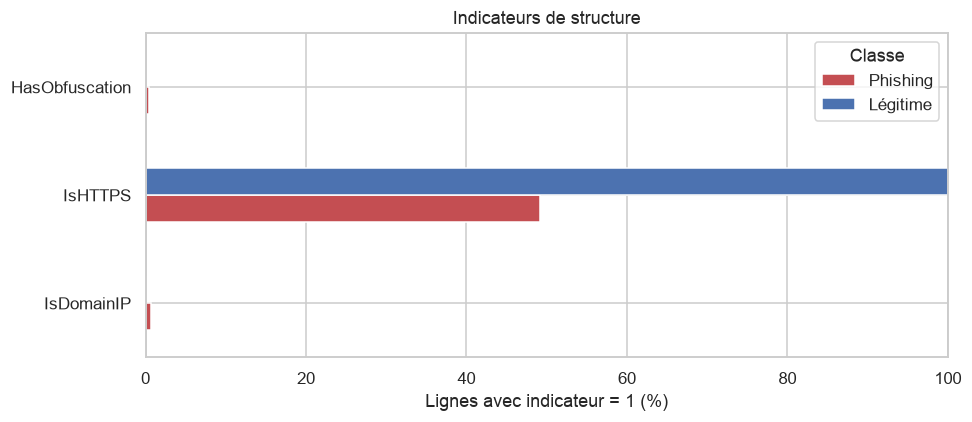

In [65]:
def compare_binary(columns, filename, title):
    rates = df.groupby("label")[columns].mean().T.rename(columns=class_names) * 100
    display(rates)
    ax = rates.plot.barh(figsize=(9, max(4, .55 * len(columns))), color=colors)
    ax.set(xlabel="Lignes avec indicateur = 1 (%)", ylabel="", xlim=(0, 100), title=title)
    ax.legend(title="Classe")
    plt.tight_layout()
    save_fig(filename)
    plt.show()

compare_binary(["IsDomainIP", "IsHTTPS", "HasObfuscation"], "04_structure_binaire", "Indicateurs de structure")

LineOfCode          NoOfImage        NoOfJS        NoOfExternalRef  \
             median     mean    median   mean median   mean          median   
label                                                                         
Phishing     12.000   65.730     0.000  0.866  0.000  0.890           0.000   
Légitime   1105.000 1947.492    25.000 44.947 14.000 17.733          46.000   

                 
           mean  
label            
Phishing  1.128  
Légitime 85.295

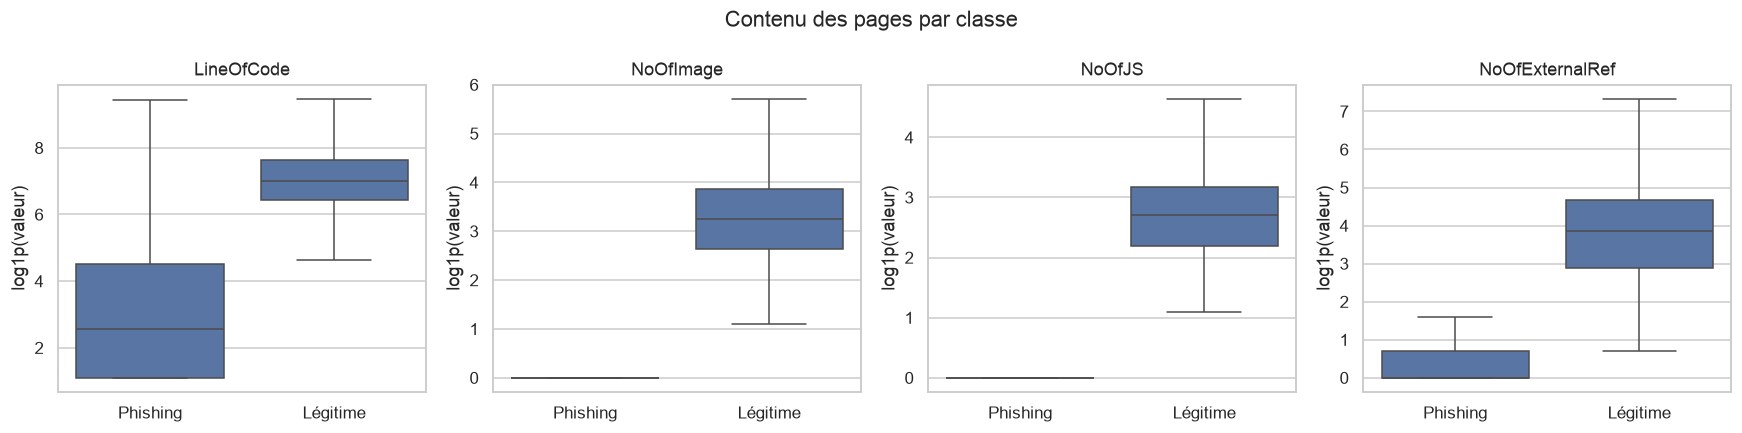

In [66]:
compare_numeric(["LineOfCode", "NoOfImage", "NoOfJS", "NoOfExternalRef"], "05_contenu_numerique", "Contenu des pages par classe")

label,Phishing,Légitime
HasTitle,67.759,99.875
HasPasswordField,5.387,13.849
HasExternalFormSubmit,0.427,7.372
HasSocialNet,0.506,79.456
HasSubmitButton,8.490,66.088


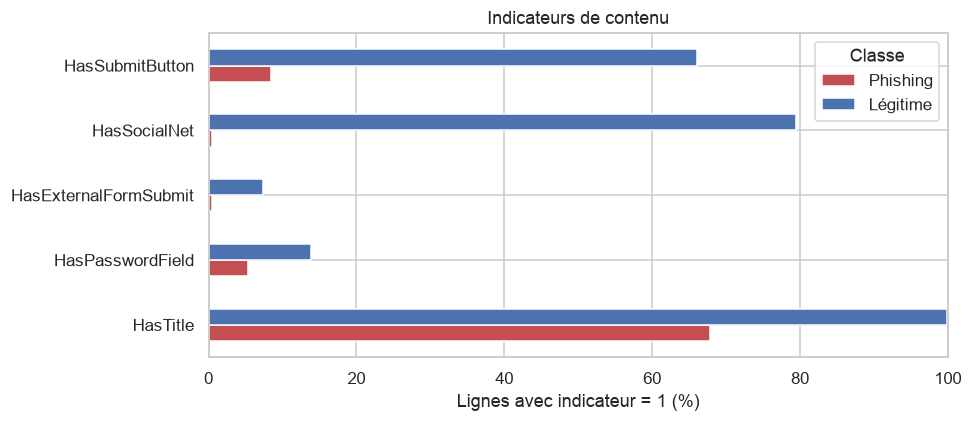

In [67]:
compare_binary(["HasTitle", "HasPasswordField", "HasExternalFormSubmit", "HasSocialNet", "HasSubmitButton"], "06_contenu_binaire", "Indicateurs de contenu")

### Interprétation
Les tableaux donnent les valeurs exactes derrière les graphiques. Une différence entre classes est une association descriptive, pas une preuve qu’une caractéristique provoque le phishing.

La longueur et la complexité des URL doivent être interprétées avec le biais identifié en section 2 : les URL légitimes observées sont réduites à leur domaine par notre test textuel. HTTPS et les formulaires sont à comparer dans les deux classes : ni la présence de HTTPS, ni celle d’un champ de mot de passe ne prouve la légitimité ou le phishing.

Les ressources de page montrent des contrastes importants, cohérents avec les proportions de zéros de la section 2. Ces variables supposent de disposer du contenu de la page : elles ne sont pas directement disponibles à partir du seul texte d’une URL. Leur intérêt pour l’application dépendra du fonctionnement retenu en période 3.

**Résultats observés :** la longueur médiane est de 34 pour le phishing, contre 26 pour les légitimes. Le nombre de sous-domaines enregistré a une médiane de 1 dans les deux classes et des moyennes proches (1,169 contre 1,162) : il n’offre pas ici un contraste comparable à la longueur.

HTTPS est présent pour 100 % des légitimes, mais aussi 49,22 % des phishing. Une adresse IP et l’obfuscation ne concernent respectivement que 0,63 % et 0,48 % des phishing : leur absence ne suffit pas à rassurer.

Les médianes de `LineOfCode` sont de 12 contre 1 105 ; celles de `NoOfImage`, de 0 contre 25. Un champ de mot de passe est même plus fréquent chez les légitimes (13,85 %) que chez les phishing (5,39 %) dans ce fichier : un indicateur intuitivement suspect doit être vérifié dans les données. Cela ne signifie pas qu’un champ de mot de passe protège du phishing.

## 6. Analyse des TLD
On distingue la fréquence d’un TLD et la proportion de phishing **parmi ses lignes**. Un TLD fréquent dans la classe phishing n’a pas nécessairement une forte proportion de phishing. La colonne `TLD` est utilisée telle quelle ; elle ne décrit pas nécessairement un suffixe public complet comme `co.uk`.

Top 10 dans chaque classe :


,Phishing
TLD,
com,43769
app,6368
co,4964
io,3769
net,3099
ru,2983
top,2327
dev,2312
org,2269


,Légitime
TLD,
com,68785
org,16524
uk,6073
net,3998
de,3310
au,2606
jp,2082
edu,1856
it,1669


label,phishing,legitime,total,phishing_pct
TLD,,,,
com,43769,68785,112554,38.887
org,2269,16524,18793,12.074
net,3099,3998,7097,43.666
app,6368,140,6508,97.849
uk,322,6073,6395,5.035
co,4964,458,5422,91.553
io,3769,432,4201,89.717
de,686,3310,3996,17.167
ru,2983,892,3875,76.981


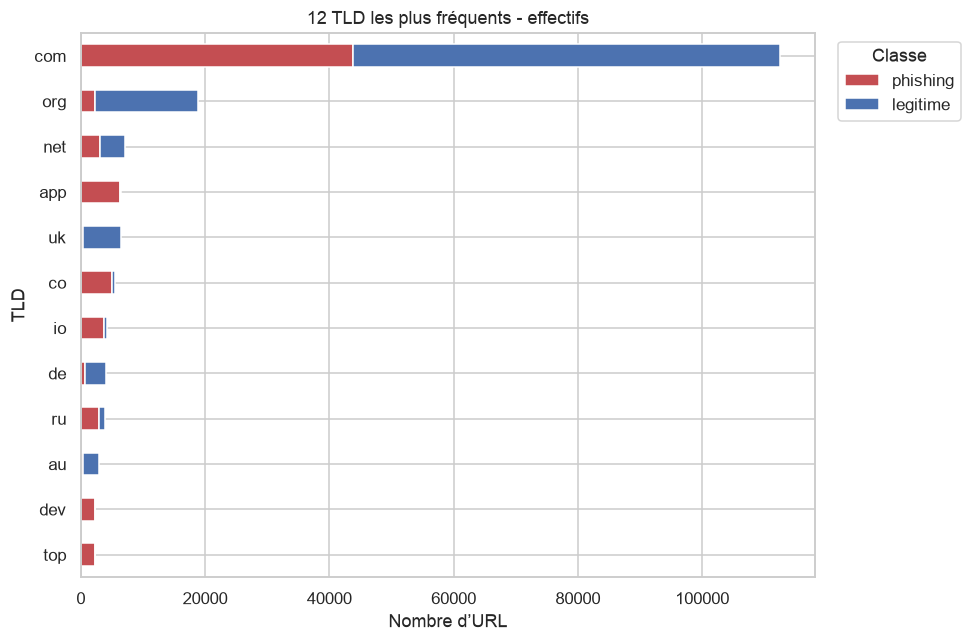

In [68]:
tld_counts = pd.crosstab(df["TLD"], df["label"]).reindex(columns=[0, 1], fill_value=0)
tld_stats = tld_counts.rename(columns={0: "phishing", 1: "legitime"})
tld_stats["total"] = tld_stats.sum(axis=1)
tld_stats["phishing_pct"] = tld_stats["phishing"] / tld_stats["total"] * 100
print("Top 10 dans chaque classe :")
for label in [0, 1]:
    display(tld_counts[label].nlargest(10).to_frame(class_names[label]))
top_tld = tld_stats.nlargest(12, "total")
display(top_tld)
ax = top_tld[["phishing", "legitime"]].plot.barh(stacked=True, figsize=(9, 6), color=colors)
ax.invert_yaxis()
ax.set(xlabel="Nombre d’URL", ylabel="TLD", title="12 TLD les plus fréquents - effectifs")
ax.legend(title="Classe", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_fig("07_tld_effectifs")
plt.show()

TLD avec au moins 100 lignes : 102
TLD exclusifs d’une classe dans ce CSV : 361


label,phishing,legitime,total,phishing_pct
TLD,,,,
icu,151,0,151,100.000
cfd,107,0,107,100.000
page,490,0,490,100.000
gq,493,0,493,100.000
cf,1203,0,1203,100.000
top,2327,2,2329,99.914
ml,994,1,995,99.899
site,1477,5,1482,99.663
ga,1107,4,1111,99.640


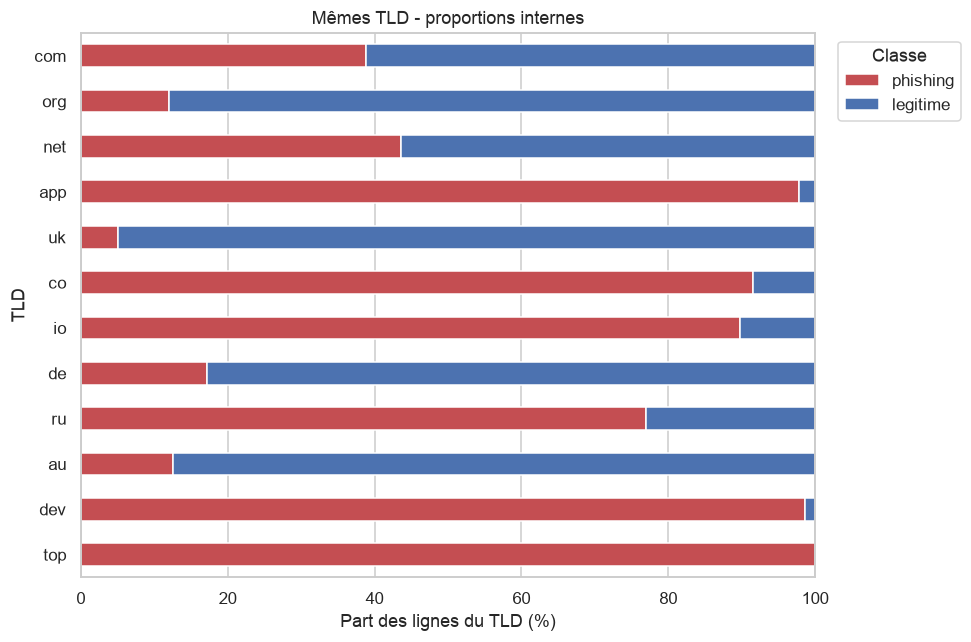

In [69]:
# Seuil descriptif de 100 observations : améliore la lisibilité, sans garantir la représentativité.
tld_suffisants = tld_stats[tld_stats["total"].ge(100)].copy()
print("TLD avec au moins 100 lignes :", len(tld_suffisants))
print("TLD exclusifs d’une classe dans ce CSV :", tld_stats["phishing_pct"].isin([0, 100]).sum())
display(tld_suffisants.sort_values("phishing_pct", ascending=False).head(10))
ax = top_tld[["phishing", "legitime"]].div(top_tld["total"], axis=0).mul(100).plot.barh(stacked=True, figsize=(9, 6), color=colors)
ax.invert_yaxis()
ax.set(xlabel="Part des lignes du TLD (%)", ylabel="TLD", xlim=(0, 100), title="Mêmes TLD - proportions internes")
ax.legend(title="Classe", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_fig("08_tld_proportions")
plt.show()

### Interprétation
`com` domine les effectifs (112 554 lignes). La figure en proportions répond à une autre question que celle en effectifs : quelle part des observations d’un TLD est étiquetée phishing ?

Une proportion de 100 % dans le CSV n’est pas une certitude pour une future URL. Les TLD rares, la collecte et les domaines répétés peuvent amplifier ces associations. Le seuil de 100 observations utilisé pour le tableau est un choix de présentation, pas une garantie statistique. Les fréquences observées ici ne sont pas des probabilités de risque dans la population réelle.

Dans le CSV, la part de phishing est de 38,89 % pour `com`, 12,07 % pour `org`, 97,85 % pour `app` et 99,91 % pour `top`. Au total, 361 TLD ne sont observés que dans une classe, et 102 TLD comptent au moins 100 lignes. Ces résultats restent conditionnés à cet échantillon.

## 7. Corrélations, redondances et signaux à auditer
Spearman mesure une association monotone fondée sur les rangs, adaptée ici aux distributions asymétriques. Avec `label = 1` pour légitime, une corrélation positive correspond à des valeurs plus élevées chez les légitimes. Une corrélation ne mesure ni un effet causal ni une importance de modèle.

,spearman_avec_label
URLSimilarityIndex,0.945
NoOfExternalRef,0.843
NoOfImage,0.843
LineOfCode,0.841
NoOfSelfRef,0.829
NoOfJS,0.823
NoOfCSS,0.803
HasSocialNet,0.784
HasCopyrightInfo,0.743
HasDescription,0.690


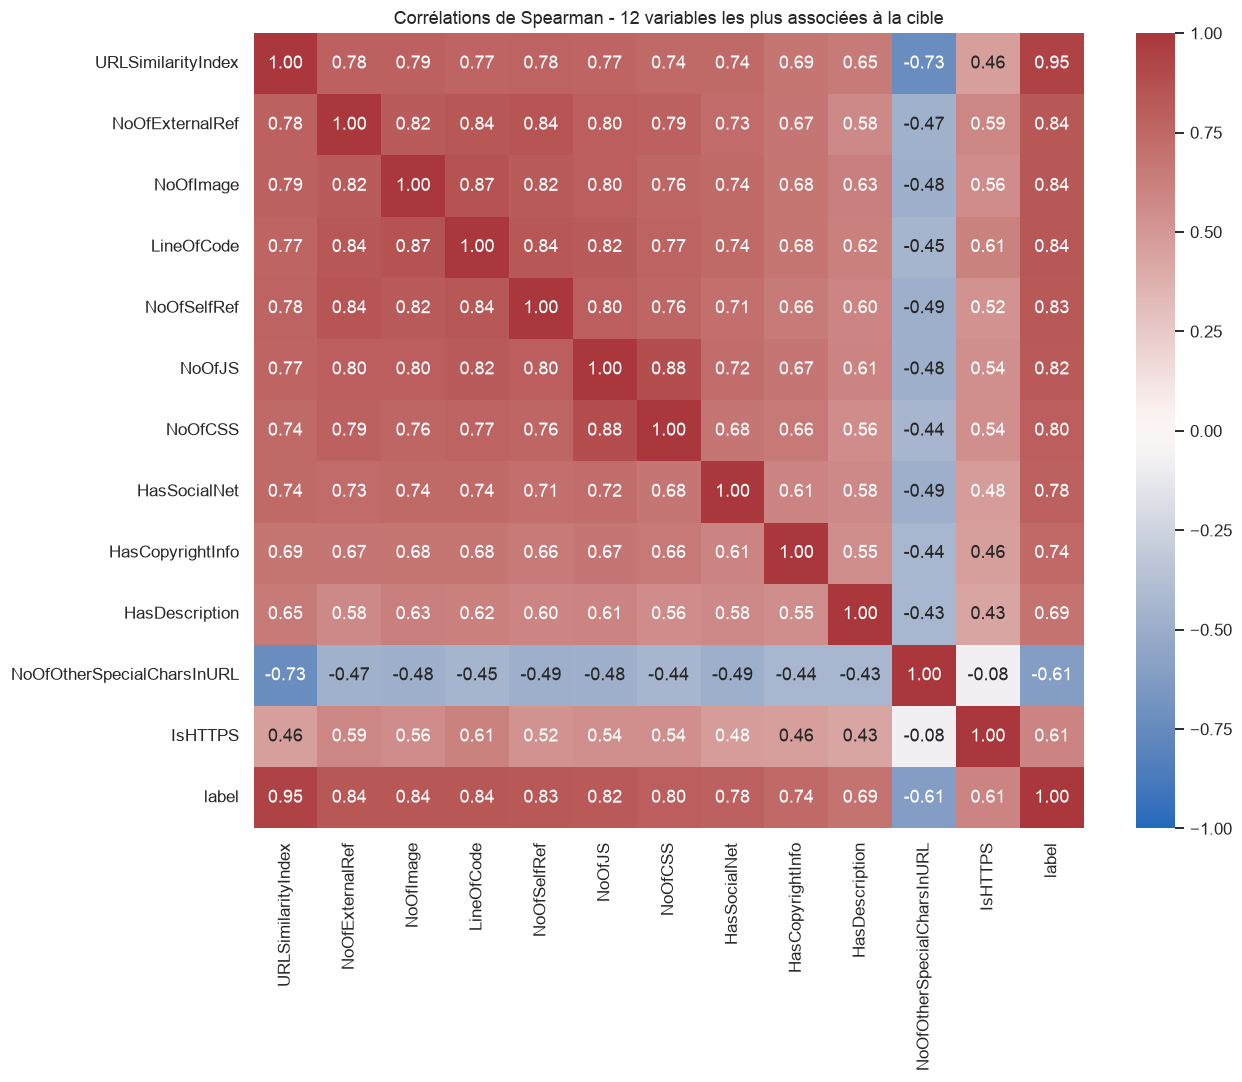

spearman
NoOfObfuscatedChar    ObfuscationRatio       1.000
HasObfuscation        NoOfObfuscatedChar     1.000
                      ObfuscationRatio       1.000
NoOfDegitsInURL       DegitRatioInURL        0.997
URLLength             NoOfLettersInURL       0.972
DomainTitleMatchScore URLTitleMatchScore     0.964
NoOfLettersInURL      LetterRatioInURL       0.931
NoOfEqualsInURL       NoOfQMarkInURL         0.910

In [70]:
corr = df[num_cols + ["label"]].corr(method="spearman")
corr_target = corr["label"].drop("label").sort_values(key=lambda s: s.abs(), ascending=False)
display(corr_target.to_frame("spearman_avec_label"))
selected = corr_target.head(12).index.tolist() + ["label"]
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr.loc[selected, selected], vmin=-1, vmax=1, center=0, cmap="vlag", annot=True, fmt=".2f", ax=ax)
ax.set_title("Corrélations de Spearman - 12 variables les plus associées à la cible")
plt.tight_layout()
save_fig("09_correlations")
plt.show()
# Le triangle supérieur évite de compter deux fois la même paire.
features_corr = corr.loc[num_cols, num_cols]
pairs = features_corr.where(np.triu(np.ones(features_corr.shape), k=1).astype(bool)).stack()
display(pairs[pairs.abs().ge(.9)].sort_values(key=lambda s: s.abs(), ascending=False).to_frame("spearman"))

In [71]:
# Examiner un signal très discriminant sans entraîner ni sélectionner de modèle.
print("URLSimilarityIndex par classe :")
display(df.groupby("label")["URLSimilarityIndex"].describe().rename(index=class_names))
print("Effectifs selon le score exactement égal à 100 :")
display(pd.crosstab(df["URLSimilarityIndex"].eq(100), df["label"]).rename(columns=class_names))
print("Proportions internes à chaque classe :")
display(pd.crosstab(df["URLSimilarityIndex"].eq(100), df["label"], normalize="columns").rename(columns=class_names))

URLSimilarityIndex par classe :


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Phishing,100945.000,49.617,22.572,0.156,32.121,51.419,67.251,100.000
Légitime,134850.000,100.000,0.000,100.000,100.000,100.000,100.000,100.000


Effectifs selon le score exactement égal à 100 :


label,Phishing,Légitime
URLSimilarityIndex,,
False,100159,0
True,786,134850


Proportions internes à chaque classe :


label,Phishing,Légitime
URLSimilarityIndex,,
False,0.992,0.000
True,0.008,1.000


### Interprétation et limites
Les fortes associations doivent être auditées avant l’entraînement. Des variables redondantes peuvent décrire le même phénomène ; une association très élevée avec la cible n’établit pas, à elle seule, une fuite de données.

La documentation UCI indique que `CharContinuationRate`, `URLTitleMatchScore`, `URLCharProb` et `TLDLegitimateProb` sont dérivées de caractéristiques existantes. Elle ne suffit pas à déterminer ici sur quel corpus leurs références ont été estimées, ni à reproduire tous les calculs. Il faut consulter la méthode des auteurs avant de garantir leur disponibilité sur une URL nouvelle. Même réserve pour la référence utilisée par `URLSimilarityIndex`.

À transmettre à l’étudiant 4 : examiner l’origine et la disponibilité de ces variables, puis comparer en période 2 des modèles avec et sans caractéristiques suspectes ou issues du contenu. Si une transformation apprend des statistiques sur les données, elle devra être ajustée uniquement sur l’entraînement.

**Limite de notre démarche :** l’EDA utilise le jeu complet. Un test issu de ce même fichier ne sera donc pas entièrement vierge d’exploration. Éviter de choisir des règles, variables et seuils sur ses résultats ; prévoir si possible un jeu externe réservé pour l’évaluation finale.

Source : [fiche officielle UCI, consultée le 28 octobre 2026](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset).

**Résultats :** la corrélation de Spearman avec la cible atteint 0,945 pour `URLSimilarityIndex`, environ 0,843 pour `NoOfExternalRef` et `NoOfImage`, contre −0,399 pour `URLLength`. Toutes les URL légitimes ont un score de similarité de 100 ; 786 URL de phishing ont également ce score (0,78 % de cette classe). Un score de 100 ne garantit donc pas la légitimité. `NoOfDegitsInURL` et `DegitRatioInURL` sont très redondantes dans ce fichier (Spearman ≈ 0,997). Les coefficients affichés à 1,000 sont arrondis ; cela n’implique pas nécessairement une identité exacte.

## 8. Anomalies, valeurs extrêmes et vérifications complémentaires
Un extrême statistique n’est pas automatiquement une donnée invalide. On conserve les observations et on documente les questions pour l’étudiant 3. Aucun site du CSV n’est visité.

URLLength  LineOfCode  LargestLineLength  NoOfImage  \
label                                                                 
Phishing 0.500     34.000      12.000            138.000      0.000   
         0.990    230.000     527.000         353128.000     19.000   
         0.999    618.960    2117.000        3281478.768     22.000   
         1.000   6097.000   29687.000       13975732.000    158.000   
Légitime 0.500     26.000    1105.000           3066.000     25.000   
         0.990     39.000   13100.000          56222.870    337.000   
         0.999     45.000   36347.966         141148.000   1212.453   
         1.000     57.000  442666.000         636010.000   8956.000   

                NoOfExternalRef  
label                            
Phishing 0.500            0.000  
         0.990           11.000  
         0.999           35.056  
         1.000          368.000  
Légitime 0.500           46.000  
         0.990          534.000  
         0.999         1572.906  
         1.000        27516.000

Trois plus grandes valeurs : URLLength


,FILENAME,URLLength,label
102933,8112261.txt,6097,0
9650,7294560.txt,5794,0
150870,oph07111.txt,4274,0


Trois plus grandes valeurs : LineOfCode


,FILENAME,LineOfCode,label
8376,687547.txt,442666,1
82201,34599.txt,440155,1
60856,26168.txt,422798,1


...

Trois plus grandes valeurs : NoOfImage


,FILENAME,NoOfImage,label
62596,178866.txt,8956,1
6887,231439.txt,7641,1
138453,132433.txt,5699,1


Trois plus grandes valeurs : NoOfExternalRef


,FILENAME,NoOfExternalRef,label
217093,160591.txt,27516,1
232845,483086.txt,24525,1
53143,48586.txt,19147,1


URLLength        LineOfCode          LargestLineLength            \
            median   mean     median     mean            median      mean   
label                                                                       
Phishing    34.000 45.720     12.000   65.730           138.000 20021.448   
Légitime    26.000 26.229   1105.000 1947.492          3066.000  7375.920   

         NoOfImage        NoOfExternalRef         
            median   mean          median   mean  
label                                             
Phishing     0.000  0.866           0.000  1.128  
Légitime    25.000 44.947          46.000 85.295

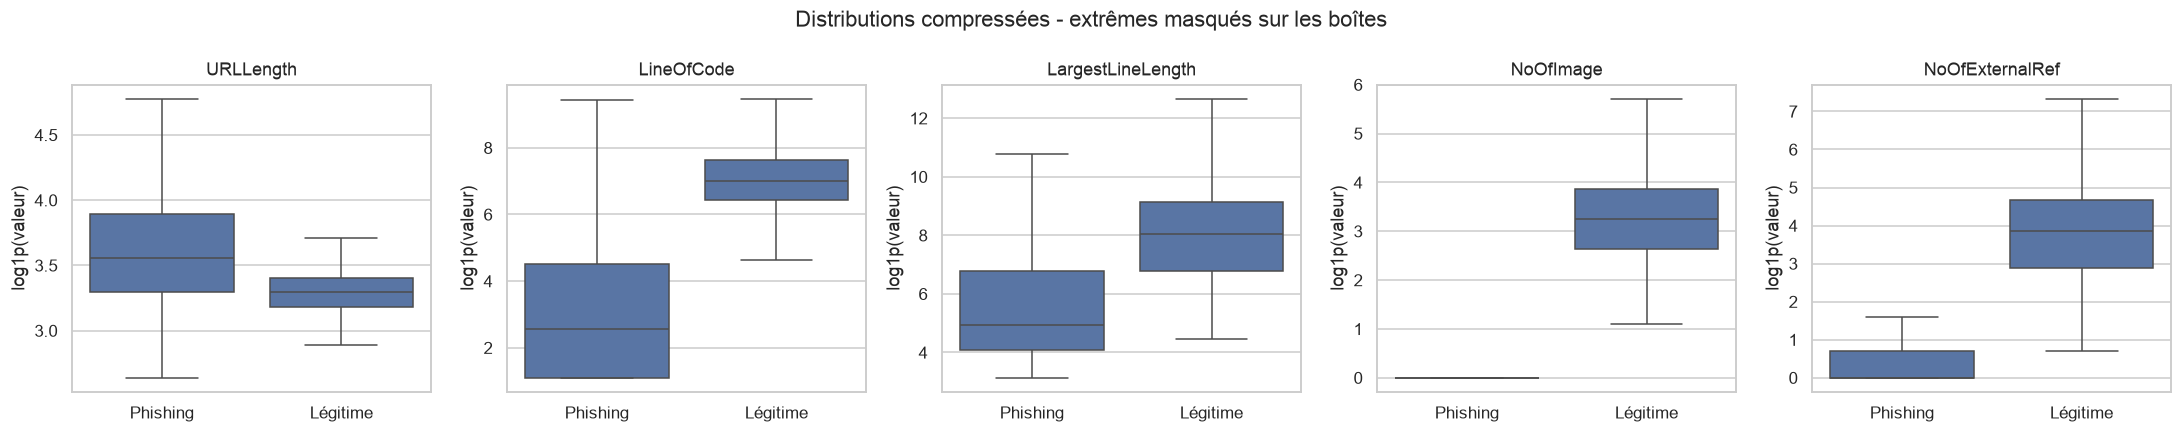

In [72]:
extreme_cols = ["URLLength", "LineOfCode", "LargestLineLength", "NoOfImage", "NoOfExternalRef"]
display(df.groupby("label")[extreme_cols].quantile([.5, .99, .999, 1]).rename(index=class_names, level=0))
for col in extreme_cols:
    print("Trois plus grandes valeurs :", col)
    display(df.loc[df[col].nlargest(3).index, ["FILENAME", col, "label"]])
compare_numeric(extreme_cols, "10_valeurs_extremes", "Distributions compressées - extrêmes masqués sur les boîtes")

In [73]:
ratio_cols = ["CharContinuationRate", "TLDLegitimateProb", "URLCharProb", "ObfuscationRatio", "LetterRatioInURL", "DegitRatioInURL", "SpacialCharRatioInURL"]
score_cols = ["URLSimilarityIndex", "DomainTitleMatchScore", "URLTitleMatchScore"]
checks = {
    "Valeurs numériques non finies": int((~np.isfinite(df[num_cols])).sum().sum()),
    "Ratios hors [0,1]": int(((df[ratio_cols] < 0) | (df[ratio_cols] > 1)).sum().sum()),
    "Scores hors [0,100]": int(((df[score_cols] < 0) | (df[score_cols] > 100)).sum().sum()),
    "Valeurs numériques négatives": int(df[num_cols].lt(0).sum().sum()),
    "DomainLength > URLLength": int(df["DomainLength"].gt(df["URLLength"]).sum()),
}
display(pd.Series(checks, name="nombre"))
# Les noms des colonnes ne suffisent pas à imposer des identités entre ratios et comptages.
# Les bornes des scores sont des attentes à confronter aux définitions des auteurs.

Valeurs numériques non finies    0
Ratios hors [0,1]                0
Scores hors [0,100]              0
Valeurs numériques négatives     0
DomainLength > URLLength         0
Name: nombre, dtype: int64

In [74]:
from urllib.parse import urlsplit

def inspect_url(value):
    try:
        parsed = urlsplit(value)
        return pd.Series({"chemin_non_racine": parsed.path not in ("", "/"),
                          "parametres": bool(parsed.query), "fragment": bool(parsed.fragment),
                          "erreur_parse": False})
    except ValueError:
        return pd.Series({"chemin_non_racine": False, "parametres": False,
                          "fragment": False, "erreur_parse": True})

url_structure = df["URL"].apply(inspect_url)
url_structure["chemin_ou_parametres"] = url_structure["chemin_non_racine"] | url_structure["parametres"]
print("Effectifs par classe pour chaque indicateur :")
display(url_structure.groupby(df["label"]).sum().rename(index=class_names))
print("Proportions (%) par classe :")
display(url_structure.groupby(df["label"]).mean().mul(100).rename(index=class_names))
# Une erreur de parsing est comptée séparément : son False n’est pas une absence confirmée.
assert len(df) == 235795
assert set(df["label"].unique()) == {0, 1}
assert df[num_cols].select_dtypes(include="number").shape[1] == len(num_cols)

Effectifs par classe pour chaque indicateur :


,chemin_non_racine,parametres,fragment,erreur_parse,chemin_ou_parametres
label,,,,,
Phishing,27456,6079,832,0,28489
Légitime,0,0,0,0,0


Proportions (%) par classe :


,chemin_non_racine,parametres,fragment,erreur_parse,chemin_ou_parametres
label,,,,,
Phishing,27.199,6.022,0.824,0.000,28.222
Légitime,0.000,0.000,0.000,0.000,0.000


### Interprétation
Les maxima dépassent nettement les quantiles élevés pour plusieurs comptages ; l’échelle logarithmique permet de comparer le centre des distributions malgré ces écarts. Les tableaux de maxima gardent les extrêmes visibles. Une minification du HTML, une page volumineuse ou un problème d’extraction sont des explications possibles, non des causes établies.

Les contrôles de bornes détectent des incohérences simples ; même s’ils ne signalent rien, ils ne valident pas la méthode d’extraction. Les scores doivent être confrontés aux définitions des auteurs.

*Vérification à relire de la section 2.5 : le tableau issu de `urlsplit` distingue effectivement chemin, paramètres et fragment, et compte les échecs de parsing. Il est plus précis que la seule égalité textuelle avec `Domain`. Ces résultats décrivent ce fichier, pas la sûreté d’un chemin ou d’un domaine sur Internet.*

**Résultats des contrôles :** aucune valeur numérique non finie, négative, aucun ratio hors des bornes attendues, aucun score hors [0,100] et aucun `DomainLength > URLLength` n’ont été détectés.

Les extrêmes ne sont pas tous dans la même classe : le maximum de longueur d’URL (6 097) est phishing, celui du nombre de lignes de code (442 666) est légitime. Pour `LargestLineLength`, la moyenne est plus élevée chez les phishing (20 021 contre 7 376), alors que leur médiane est plus faible (138 contre 3 066) : quelques extrêmes inversent la comparaison des moyennes.

*Correction à relire de la section 2.5 : `urlsplit` trouve 27 456 phishing avec un chemin non racine, 6 079 avec des paramètres et 28 489 avec l’un ou l’autre (28,22 %). Les catégories se recouvrent. Le premier test trouvait 28 689 inégalités textuelles : les 200 cas d’écart ne doivent pas être présentés comme des chemins ou paramètres confirmés. Il n’y a aucune erreur de parsing. Chez les légitimes, les trois indicateurs chemin non racine, paramètres et fragment sont tous nuls.*

## 9. Synthèse générale et transmissions

| Sujet | Constat / action proposée | Destinataire |
|---|---|---|
| Cible | 0 = phishing ; 1 = légitime. Préciser la classe positive des métriques | Étudiants 1 et 4 |
| Équilibre | 42,8 % phishing ; 57,2 % légitimes. Accuracy majoritaire : 57,2 % | Étudiant 4 |
| Titres | 32 714 absences indiquées par HasTitle avec Title="0" ; cinq autres titres "0" à examiner | Étudiant 3 |
| Doublons | 425 URL distinctes répétées, 850 lignes concernées, caractéristiques différentes | Étudiants 3 et 4 |
| Domaines | 5 526 domaines répétés dont 54 mixtes ; tenir compte des hôtes et si pertinent des domaines enregistrables | Étudiant 4 |
| Longueurs | Écart entre longueur du texte et URLLength dépendant de la classe | Étudiants 1 et 3 |
| Forme des URL | Faible diversité des formes légitimes ; vérifier la généralisation aux pages profondes | Étudiants 4, périodes 2 et 3 |
| Distributions | Fortes asymétries et modalités très majoritaires ; ne pas supprimer automatiquement les extrêmes ou signaux rares | Étudiant 3 |
| TLD | 695 modalités, dont 408 présentes moins de 10 fois ; prudence sur les proportions des petits groupes | Étudiants 3 et 4 |
| Variables dérivées | Auditer références de calcul, disponibilité et risque de fuite avant la modélisation | Étudiants 1 et 4 |
| Contenu | Nécessite le HTML ; fortes différences de présence de ressources entre classes | Périodes 2 et 3 |

### Ce que cette analyse permet de conclure
Le fichier présente des associations exploitables mais aussi des particularités susceptibles de faciliter artificiellement la classification. Les observations justifient une évaluation attentive aux doublons, aux groupes de domaines et à la disponibilité réelle des variables. Elles ne démontrent pas les performances d’un futur modèle.

### Limites et suite du projet
L’analyse est descriptive et réalisée sur tout le CSV. Aucun modèle n’est entraîné, aucune donnée n’est nettoyée, aucun split n’est créé. La collecte, les dates individuelles et les définitions détaillées de certaines variables restent insuffisamment documentées dans cette analyse. Les périodes 2 et 3 devront examiner faux positifs, faux négatifs, calibration, incertitude, robustesse aux variations d’URL et généralisation externe.

### Relecture avant rendu
Les mentions *Correction à relire* identifient les nuances ajoutées au travail précédent. Relire les sorties, les figures et les interprétations ; reformuler avec ses propres mots. Pour reproduire : ouvrir ce notebook depuis `periode-1/notebooks/`, redémarrer le noyau puis exécuter toutes les cellules. Les figures sont enregistrées dans `../reports/figures/`.
